# Part 3: Trip-level models
LightGBM models for trip duration, metered fare and card tip %, using only what's known at booking. Train before Mar 2026, validate Mar to May, test Jun to Aug. Each model is compared with a route-and-hour baseline, then explained with SHAP.

Part of [NYC Yellow Cab: demand, pricing and forecasting](../README.md). Next: [Part 4, forecasting](P4_forecast.ipynb).

In [1]:
# Phase 3
import os, sys, json, zipfile, urllib.request
from pathlib import Path
import duckdb, pandas as pd, numpy as np
import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.metrics import mean_absolute_error, mean_squared_error, roc_auc_score

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")

BASE = Path(os.environ.get('NYC_TAXI_BASE', '/content/drive/MyDrive/nyc-yellow-cab'))
MODELS, FIGS = BASE / 'models', BASE / 'figures'
MODELS.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)
con = duckdb.connect(str(BASE / 'taxi.duckdb'), read_only=True)
# 5% ~ 4M rows on 24 months for iteration, 15-20 for the final run
SAMPLE_PCT = 15
SEED = 42

C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK, "lines.linewidth": 2,
    "legend.frameon": False, "axes.prop_cycle": plt.cycler(color=C),
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")
    plt.show()

Mounted at /content/drive


In [2]:
# 3.1 data split
months = con.sql("SELECT DISTINCT DATE_TRUNC('month', pu_date)::DATE AS m FROM trips ORDER BY 1").df().m
# reserve last 3 months for test, the 3 before for validation
if len(months) >= 7:
  VAL_START, TEST_START = months.iloc[-6], months.iloc[-3]
# dev mode, 70%/15%/15% split
else:
  days = con.sql('SELECT DISTINCT pu_date::DATE AS d FROM trips ORDER BY 1').df().d
  VAL_START, TEST_START = days.iloc[int(len(days) * 0.70)], days.iloc[int(len(days) * 0.85)]
  print("Fewer than 7 months loaded: splitting by days. Use the full 24 months for real results.")
print(f'train < {VAL_START} < validate < {TEST_START} < test')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

train < 2026-03-01 00:00:00 < validate < 2026-06-01 00:00:00 < test


In [3]:
# 3.2 Zone centers
shp_dir = BASE / 'raw' / 'taxi_zones'
if not shp_dir.exists():                       # Phase 2 normally downloaded this already
    shp_zip = BASE / "raw" / "taxi_zones.zip"
    if not shp_zip.exists():
        urllib.request.urlretrieve("https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip", shp_zip)
    zipfile.ZipFile(shp_zip).extractall(shp_dir)
import geopandas as gpd
gdf = gpd.read_file(next(shp_dir.rglob('*.shp'))).to_crs(2263) # lat,lon to linear distance in feet
gdf.columns = [c.lower() for c in gdf.columns]
cent = (gdf.dissolve(by='locationid').centroid.to_frame('geometry')
        .assign(x_mi=lambda d: d.geometry.x / 5280, y_mi=lambda d: d.geometry.y / 5280)
        .reset_index()[['locationid','x_mi','y_mi']])
con.register('cent', cent)
cent.head()

,locationid,x_mi,y_mi
0,1,177.272125,36.245597
1,2,195.281386,31.064158
2,3,194.403905,48.156341
3,4,187.620072,38.439353
4,5,176.490790,26.644195


In [4]:
# 3.3 Build modeling table
df = con.sql(f"""
  SELECT
    CASE WHEN t.pu_date < '{VAL_START}'::DATE THEN 'train'
         WHEN t.pu_date < '{TEST_START}'::DATE THEN 'val'
         ELSE 'test' END AS split,
    t.pulocationid AS pu_zone_id, t.dolocationid AS do_zone_id,
    t.pu_hour, t.pu_dow, t.month, t.is_weekend::INT AS is_weekend, t.is_holiday::INT AS is_holiday,
    t.is_airport::INT AS is_airport, t.touches_cbd::INT AS touches_cbd,
    t.post_congestion_pricing::INT AS post_cp,
    pc.x_mi AS pu_x, pc.y_mi AS pu_y, dc.x_mi AS do_x, dc.y_mi AS do_y,
    SQRT(POWER(pc.x_mi - dc.x_mi, 2) + POWER(pc.y_mi - dc.y_mi, 2)) AS centroid_miles,
    (t.pulocationid = t.dolocationid)::INT AS same_zone,
    COALESCE(t.passenger_count, 1) AS passengers,
    t.ratecodeid, t.payment_type, t.pu_borough,
    t.duration_min, t.fare_amount, t.tip_amount, t.tip_pct
  FROM trips t
  JOIN cent pc ON pc.locationid = t.pulocationid
  JOIN cent dc ON dc.locationid = t.dolocationid
  WHERE HASH(t.tpep_pickup_datetime, t.pulocationid, t.dolocationid, t.fare_amount) % 1000 < {SAMPLE_PCT * 10}
""").df()

for c in['pu_zone_id','do_zone_id']:
  df[c] = df[c].astype('category')
print(df.split.value_counts().to_string())
print(f"{len(df):,} rows, {df.memory_usage(deep=True).sum() / 1e9:.2f} GB in memory")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

split
train    9614770
val      1679066
test     1497932
12,791,768 rows, 3.18 GB in memory


In [5]:
# 3.4 Helpers function
BASE_FEATURES = ["pu_zone_id", "do_zone_id", "pu_hour", "pu_dow", "month", "is_weekend", "is_holiday",
                 "is_airport", "touches_cbd", "post_cp", "pu_x", "pu_y", "do_x", "do_y",
                 "centroid_miles", "same_zone"]
PARAMS = dict(learning_rate=0.08, num_leaves=127, min_data_in_leaf=200, feature_fraction=0.9,
              bagging_fraction=0.8, bagging_freq=1, cat_smooth=20, verbose=-1, seed=SEED)
RESULTS, BOOSTERS = [], {}
# Hierarchical fallback baseline
def group_baseline(train, target, keys, how='median', min_count=5):
  # keys: orders from most important to least; each iteration drops the key that matters the least
  # min_count: Predict the train-set median (or mean) for each group with at least min_count trips
  tables = []
  for lv in [keys[:i] for i in range(len(keys), 0, -1)]:
    g = train.groupby(lv, observed=True)[target]
    tables.append((lv, g.agg(how)[g.size() >= min_count].rename('_b')))
  global_value = train[target].agg(how)
  def predict(frame):
    pred = pd.Series(np.nan, index = frame.index)
    for lv, table in tables:
      fill = frame[lv].merge(table, left_on=lv, right_index=True, how='left')['_b']
      pred = pred.fillna(fill)
    return pred.fillna(global_value)
  return predict
# model training
def fit(name, data, features, target, objective='regression', metric='l1'):
  tr, va = data[data.split == 'train'], data[data.split == 'val']
  model = lgb.train(
      {**PARAMS, 'objective': objective, 'metric': metric}, #params
      lgb.Dataset(tr[features], tr[target]),
      num_boost_round=3000, # max n trees
      valid_sets=[lgb.Dataset(va[features], va[target])],
      callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(200)]
  )
  BOOSTERS[name] = (model, features)
  print(f'{name}: best iteration {model.best_iteration}')
  return model
# Evaluations
def report(model_name, y, pred, base, unit):
  row = dict(model = model_name, unit = unit,
             baseline_MAE = mean_absolute_error(y, base),
             model_MAE = mean_absolute_error(y, pred),
             baseline_RMSE = mean_squared_error(y, base) ** .5,
             model_RMSE = mean_squared_error(y, pred) ** .5)
  row['MAE_improvement_%'] = 100.0 * (1 - row['model_MAE'] / row['baseline_MAE'])
  RESULTS.append(row)
  print({k: round(v, 3) if isinstance(v, float) else v for k, v in row.items()})


In [6]:
# 3.5 Model 1, trip duration
dur = df.copy()
dur['log_dur'] = np.log(dur.duration_min)
# fit(name, data, features, target, objective='regression', metric='l1')
m_dur = fit('duration', dur, BASE_FEATURES, 'log_dur', objective='regression', metric='l1')
test = dur[dur.split == 'test']
pred_dur = np.exp(m_dur.predict(test[BASE_FEATURES], num_iteration=m_dur.best_iteration))
base_dur = group_baseline(dur[dur.split == 'train'], 'duration_min', ['pu_zone_id', 'do_zone_id', 'pu_hour'])(test)
report('M1: Duration', test.duration_min, pred_dur, base_dur, 'minutes')
dur_test = test.assign(pred=pred_dur, base=base_dur)


[200]	valid_0's l1: 0.260392
[400]	valid_0's l1: 0.25905
[600]	valid_0's l1: 0.258591
[800]	valid_0's l1: 0.258257
[1000]	valid_0's l1: 0.258071
[1200]	valid_0's l1: 0.257959
[1400]	valid_0's l1: 0.257873
[1600]	valid_0's l1: 0.257806
[1800]	valid_0's l1: 0.257767
[2000]	valid_0's l1: 0.257722
duration: best iteration 1997
{'model': 'M1: Duration', 'unit': 'minutes', 'baseline_MAE': 4.1, 'model_MAE': 3.736, 'baseline_RMSE': 6.419, 'model_RMSE': 5.841, 'MAE_improvement_%': 8.873}


In [7]:
# 3.6 Model 2, fare
fare = df[(df.ratecodeid == 1) & (df.fare_amount > 0)].copy()
m_fare = fit('fare', fare, BASE_FEATURES, 'fare_amount', objective='huber', metric='l1')

test = fare[fare.split == 'test']
pred_fare = m_fare.predict(test[BASE_FEATURES], num_iteration=m_fare.best_iteration)
base_fare = group_baseline(fare[fare.split == 'train'], 'fare_amount', ['pu_zone_id', 'do_zone_id', 'pu_hour'])(test)
report('M2: Fare', test.fare_amount, pred_fare, base_fare, '$')
fare_test = test.assign(pred=pred_fare, base=base_fare)

[200]	valid_0's l1: 3.77832
[400]	valid_0's l1: 3.01122
[600]	valid_0's l1: 2.79911
[800]	valid_0's l1: 2.71568
[1000]	valid_0's l1: 2.68642
[1200]	valid_0's l1: 2.67444
[1400]	valid_0's l1: 2.66688
[1600]	valid_0's l1: 2.66198
[1800]	valid_0's l1: 2.65844
[2000]	valid_0's l1: 2.65549
[2200]	valid_0's l1: 2.65302
[2400]	valid_0's l1: 2.65107
[2600]	valid_0's l1: 2.64937
[2800]	valid_0's l1: 2.64801
[3000]	valid_0's l1: 2.64688
fare: best iteration 3000
{'model': 'M2: Fare', 'unit': '$', 'baseline_MAE': 2.893, 'model_MAE': 2.727, 'baseline_RMSE': 4.853, 'model_RMSE': 4.357, 'MAE_improvement_%': 5.75}


In [8]:
# 3.7 Model 3, tip on card trips
tips = df[(df.payment_type == 1) & (df.fare_amount >= 3)].copy()
tips['tip_pct_c'] = tips.tip_pct.clip(0, 100) # capping values between 0% and 100%
tips['big_tip'] = (tips.tip_pct >= 20).astype(int)
TIP_FEATURES = BASE_FEATURES + ['fare_amount', 'passengers']

m_tip = fit('tip_pct', tips, TIP_FEATURES, 'tip_pct_c', objective='huber', metric='l1')
test = tips[tips.split == 'test']
pred_tip = m_tip.predict(test[TIP_FEATURES], num_iteration=m_tip.best_iteration)
base_tip = group_baseline(tips[tips.split == 'train'], 'tip_pct_c', ['fare_amount','pu_hour'], how='mean')(test)
report('M3: Tip', test.tip_pct_c, pred_tip, base_tip, 'pct points')

m_big = fit('big_tip', tips, TIP_FEATURES, 'big_tip', objective='binary', metric='auc')
p_big = m_big.predict(test[TIP_FEATURES], num_iteration=m_big.best_iteration)
p_base = group_baseline(tips[tips.split == 'train'], 'big_tip', ['pu_hour'], how='mean')(test)
auc, auc_base = roc_auc_score(test.big_tip, p_big), roc_auc_score(test.big_tip, p_base)
print(f"Tips ≥ 20% classifier: AUC {auc:.3f} vs. {auc_base:.3f} for the hour-only baseline "
      f"({100 * test.big_tip.mean():.0f}% of test card trips tip ≥ 20%)")

[200]	valid_0's l1: 7.13989
[400]	valid_0's l1: 6.32095
[600]	valid_0's l1: 6.21081
[800]	valid_0's l1: 6.18323
[1000]	valid_0's l1: 6.16898
[1200]	valid_0's l1: 6.15941
[1400]	valid_0's l1: 6.15191
[1600]	valid_0's l1: 6.14671
[1800]	valid_0's l1: 6.14232
[2000]	valid_0's l1: 6.13787
[2200]	valid_0's l1: 6.13483
[2400]	valid_0's l1: 6.13192
[2600]	valid_0's l1: 6.12938
[2800]	valid_0's l1: 6.12661
[3000]	valid_0's l1: 6.1245
tip_pct: best iteration 2999
{'model': 'M3: Tip', 'unit': 'pct points', 'baseline_MAE': 8.106, 'model_MAE': 6.838, 'baseline_RMSE': 11.261, 'model_RMSE': 11.538, 'MAE_improvement_%': 15.649}
[200]	valid_0's auc: 0.689475
[400]	valid_0's auc: 0.68955
big_tip: best iteration 315
Tips ≥ 20% classifier: AUC 0.625 vs. 0.520 for the hour-only baseline (75% of test card trips tip ≥ 20%)


,unit,baseline_MAE,model_MAE,baseline_RMSE,model_RMSE,MAE_improvement_%
model,,,,,,
M1: Duration,minutes,4.100,3.736,6.419,5.841,8.873
M2: Fare,$,2.893,2.727,4.853,4.357,5.750
M3: Tip,pct points,8.106,6.838,11.261,11.538,15.649


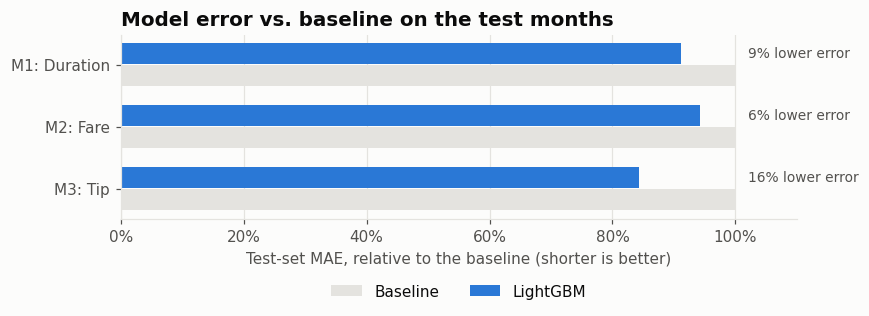

In [9]:
# 3.8 Results
res = pd.DataFrame(RESULTS).set_index("model")
display(res.round(3))

fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(res))
ax.barh(y + 0.18, res.baseline_MAE / res.baseline_MAE, height=0.34, color=GRID, label="Baseline")
ax.barh(y - 0.18, res.model_MAE / res.baseline_MAE, height=0.34, color=C[0], label="LightGBM")
for yi, imp in zip(y, res["MAE_improvement_%"]):
    label = (f"{imp:.0f}% lower error" if imp >= 0.5 else
             f"{-imp:.0f}% higher error" if imp <= -0.5 else "no change")
    ax.text(1.02, yi - 0.18, label, va="center", fontsize=9, color=INK2)
ax.set_yticks(y, res.index)
ax.invert_yaxis()
ax.set_xlim(0, 1.1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Test-set MAE, relative to the baseline (shorter is better)")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=2)
ax.set_title("Model error vs. baseline on the test months")
save(fig, "10_model_vs_baseline")

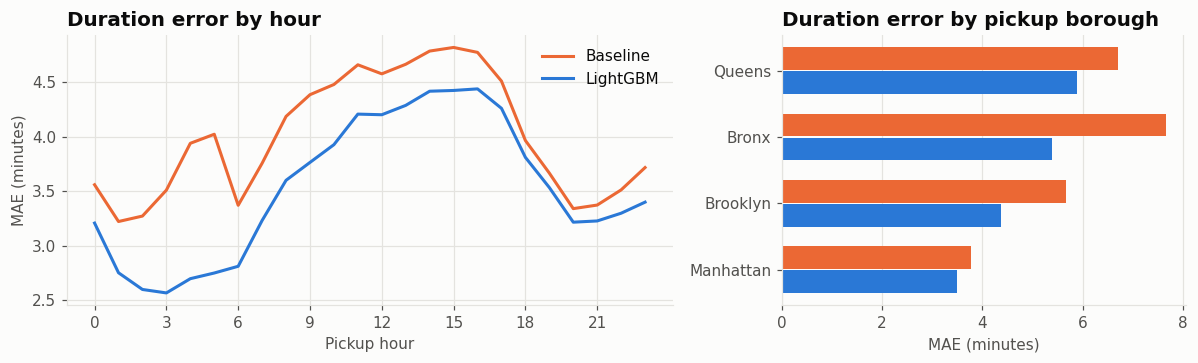

In [10]:
# 3.9 Error analysis
err = dur_test.assign(model_err=lambda d: (d.pred - d.duration_min).abs(),
                      base_err=lambda d: (d.base - d.duration_min).abs())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [3, 2]})
by_hour = err.groupby("pu_hour")[["model_err", "base_err"]].mean()
a1.plot(by_hour.index, by_hour.base_err, color=C[1], label="Baseline")
a1.plot(by_hour.index, by_hour.model_err, color=C[0], label="LightGBM")
a1.set_xticks(range(0, 24, 3))
a1.set_xlabel("Pickup hour")
a1.set_ylabel("MAE (minutes)")
a1.legend()
a1.set_title("Duration error by hour")
by_boro = (err[err.pu_borough.isin(["Manhattan", "Queens", "Brooklyn", "Bronx"])]
           .groupby("pu_borough")[["model_err", "base_err"]].mean().sort_values("model_err"))
yb = np.arange(len(by_boro))
a2.barh(yb + 0.18, by_boro.base_err, height=0.34, color=C[1], label="Baseline")
a2.barh(yb - 0.18, by_boro.model_err, height=0.34, color=C[0], label="LightGBM")
a2.set_yticks(yb, by_boro.index)
a2.grid(axis="y", visible=False)
a2.set_xlabel("MAE (minutes)")
a2.set_title("Duration error by pickup borough")
save(fig, "11_duration_error_breakdown")

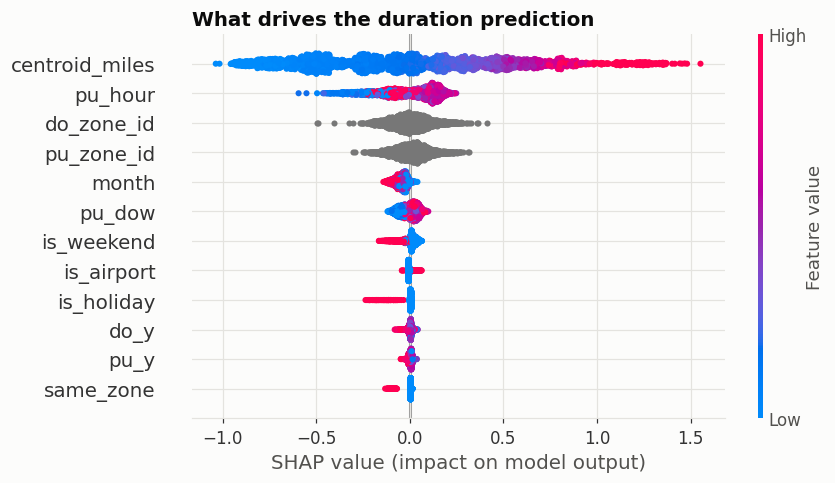

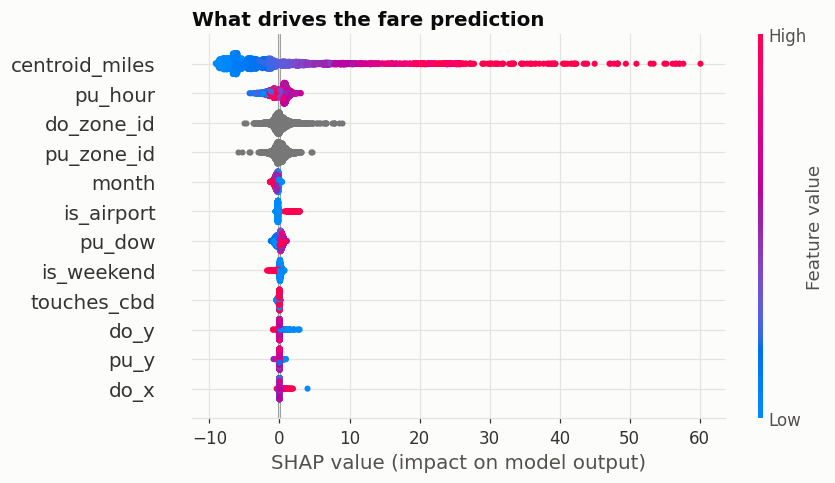

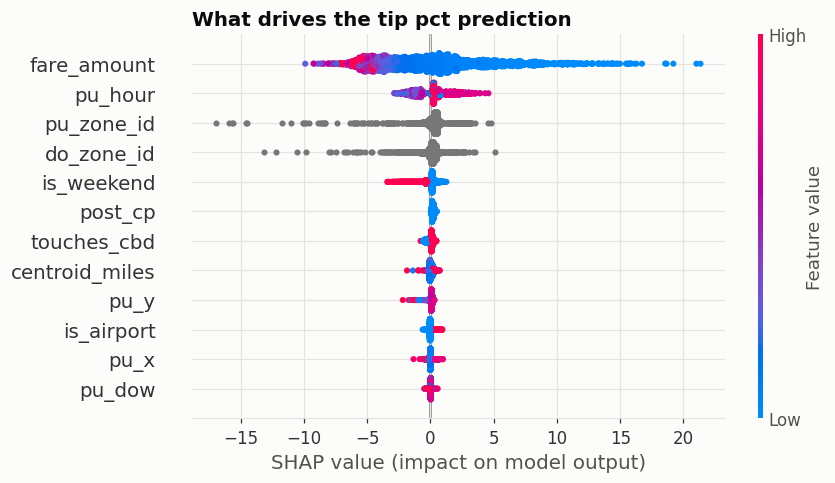

In [11]:
# 3.10 Tracking what drives predictions
import shap
for name in ["duration", "fare", "tip_pct"]:
    model, feats = BOOSTERS[name]
    src = {"duration": dur, "fare": fare, "tip_pct": tips}[name]
    X = src[src.split == "test"][feats].sample(min(3000, (src.split == "test").sum()), random_state=SEED)
    sv = shap.TreeExplainer(model).shap_values(X)
    plt.figure()
    shap.summary_plot(sv, X, max_display=12, show=False, plot_size=(8, 4.5))
    plt.title(f"What drives the {name.replace('_', ' ')} prediction", loc="left", fontweight="bold")
    save(plt.gcf(), f"12_shap_{name}")

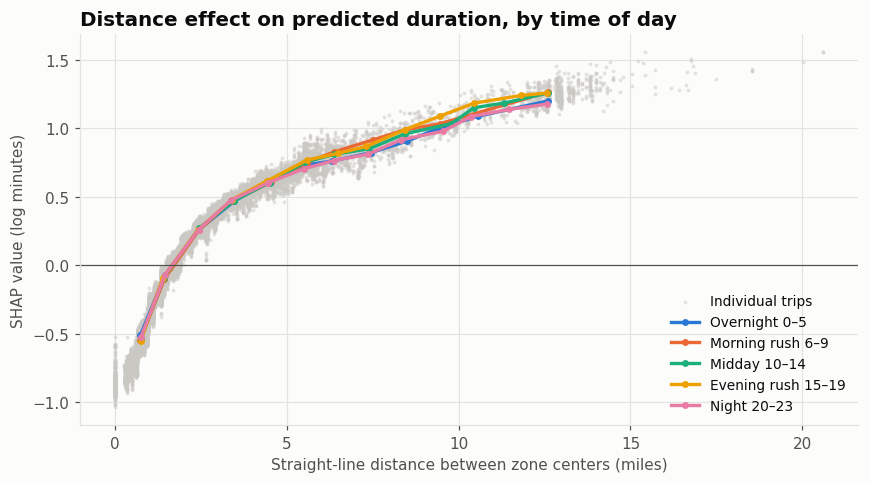

In [12]:
# 3.11 SHAP for distance, one median line per time-of-day period
model, feats = BOOSTERS["duration"]
X = dur[dur.split == "test"][feats].sample(20000, random_state=SEED)
sv = shap.TreeExplainer(model).shap_values(X)

LABELS = ["Overnight 0–5", "Morning rush 6–9", "Midday 10–14", "Evening rush 15–19", "Night 20–23"]
d = pd.DataFrame({"miles": X.centroid_miles.to_numpy(),
                  "shap": sv[:, feats.index("centroid_miles")],
                  "period": pd.cut(X.pu_hour.to_numpy(), [-1, 5, 9, 14, 19, 23], labels=LABELS)})
bins = np.arange(0, d.miles.quantile(0.99) + 1, 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(d.miles, d.shap, s=6, color="#c9c8c3", alpha=0.5, linewidths=0, label="Individual trips")
for i, (period, g) in enumerate(d.groupby("period", observed=True)):
    line = g.groupby(pd.cut(g.miles, bins), observed=True).agg(
        miles=("miles", "median"), shap=("shap", "median"), n=("shap", "size"))
    line = line[line.n >= 20]                     # skip thin bins so the lines don't zigzag
    ax.plot(line.miles, line.shap, color=C[i], lw=2.2, marker="o", ms=3.5, label=period)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xlabel("Straight-line distance between zone centers (miles)")
ax.set_ylabel("SHAP value (log minutes)")
ax.legend(fontsize=9, loc="lower right")
ax.set_title("Distance effect on predicted duration, by time of day")
save(fig, "12b_shap_distance_by_period")

In [14]:
# 3.12 Save
import re
short = lambda m: re.split(r"\s*[·:]\s*", m)[-1]          # "M1: Duration" or "A · Duration" -> "Duration"
metrics = {**res.round(4).to_dict(orient="index"),
           "big_tip_classifier": {"AUC": round(auc, 4), "baseline_AUC": round(auc_base, 4)},
           "config": {"sample_pct": SAMPLE_PCT, "val_start": str(VAL_START), "test_start": str(TEST_START),
                      "train_rows": int((df.split == "train").sum())}}
(MODELS / "test_metrics.json").write_text(json.dumps(metrics, indent=2))
for name, (model, feats) in BOOSTERS.items():
    model.save_model(str(MODELS / f"{name}.txt"), num_iteration=model.best_iteration)

run = {"run_at": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "sample_pct": SAMPLE_PCT,
       "train_rows": int((df.split == "train").sum()), "test_start": str(TEST_START),
       **{f"{k}": PARAMS[k] for k in ["learning_rate", "num_leaves", "min_data_in_leaf"]},
       **{f"{short(m)} MAE": round(r.model_MAE, 3) for m, r in res.iterrows()},
       **{f"{short(m)} baseline MAE": round(r.baseline_MAE, 3) for m, r in res.iterrows()},
       "big_tip AUC": round(auc, 3), "big_tip baseline AUC": round(auc_base, 3)}
log_path = MODELS / "experiment_log.csv"
pd.DataFrame([run]).to_csv(log_path, mode="a", header=not log_path.exists(), index=False)
print(json.dumps(metrics, indent=2))
print(f"Models saved to {MODELS}")
pd.read_csv(log_path).tail()

{
  "M1: Duration": {
    "unit": "minutes",
    "baseline_MAE": 4.0998,
    "model_MAE": 3.736,
    "baseline_RMSE": 6.4186,
    "model_RMSE": 5.8409,
    "MAE_improvement_%": 8.8734
  },
  "M2: Fare": {
    "unit": "$",
    "baseline_MAE": 2.8932,
    "model_MAE": 2.7268,
    "baseline_RMSE": 4.8533,
    "model_RMSE": 4.3569,
    "MAE_improvement_%": 5.7497
  },
  "M3: Tip": {
    "unit": "pct points",
    "baseline_MAE": 8.1063,
    "model_MAE": 6.8378,
    "baseline_RMSE": 11.2609,
    "model_RMSE": 11.538,
    "MAE_improvement_%": 15.6485
  },
  "big_tip_classifier": {
    "AUC": 0.6254,
    "baseline_AUC": 0.5202
  },
  "config": {
    "sample_pct": 15,
    "val_start": "2026-03-01 00:00:00",
    "test_start": "2026-06-01 00:00:00",
    "train_rows": 9614770
  }
}
Models saved to /content/drive/MyDrive/nyc-yellow-cab/models


,run_at,sample_pct,train_rows,test_start,learning_rate,num_leaves,min_data_in_leaf,Duration MAE,Fare MAE,Tip MAE,Duration baseline MAE,Fare baseline MAE,Tip baseline MAE,big_tip AUC,big_tip baseline AUC
0,2026-10-20 00:15,15,9614770,2026-06-01 00:00:00,0.08,127,200,3.736,2.727,6.838,4.1,2.893,8.106,0.625,0.52
